In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from itertools import combinations

from patchdataset import get_labeled_data

We use two labeled images (O013257 and O012791) for feature selection. The third labeled image (O013490) is reserved for final testing and excluded from this analysis.

We evaluate eight original features: NDAI, SD, CORR, DF, CF, BF, AF, and AN.

In [4]:
IMAGE_1 = "O013257.npz"
IMAGE_2 = "O012791.npz"

FEATURES = ["NDAI", "SD", "CORR", "DF", "CF", "BF", "AF", "AN"]

In [6]:
X1, y1 = get_labeled_data([IMAGE_1])
X2, y2 = get_labeled_data([IMAGE_2])

print("Image 1:", X1.shape, y1.shape)
print("Image 2:", X2.shape, y2.shape)

Image 1: (70826, 8) (70826,)
Image 2: (54772, 8) (54772,)


Image 1 contains 70,826 labeled pixels, and Image 2 contains 54,772 labeled pixels. Each observation has eight features and one binary cloud label (-1 for non-cloud and +1 for cloud).

Calculate the ROC-AUC for each feature in both images. We use max(AUC, 1 − AUC) to measure each feature's ability to distinguish clouds from non-clouds, regardless of the direction of the relationship.

In [7]:
results = []

for i, feature in enumerate(FEATURES):
    auc1 = roc_auc_score(y1, X1[:, i])
    auc2 = roc_auc_score(y2, X2[:, i])

    results.append([
        feature,
        max(auc1, 1 - auc1),
        max(auc2, 1 - auc2)
    ])

auc_df = pd.DataFrame(
    results,
    columns=["Feature", "Image 1 AUC", "Image 2 AUC"]
)

auc_df["Mean AUC"] = auc_df[["Image 1 AUC", "Image 2 AUC"]].mean(axis=1)

auc_df = auc_df.sort_values("Mean AUC", ascending=False)

auc_df.round(3)

,Feature,Image 1 AUC,Image 2 AUC,Mean AUC
1,SD,0.957,0.882,0.919
3,DF,0.829,0.693,0.761
7,AN,0.798,0.674,0.736
6,AF,0.843,0.610,0.726
4,CF,0.854,0.597,0.725
0,NDAI,0.547,0.827,0.687
5,BF,0.861,0.503,0.682
2,CORR,0.738,0.534,0.636


### Result
SD shows the strongest individual discriminatory power, with a mean AUC of 0.919 (0.957 in Image 1 and 0.882 in Image 2). DF (0.761) and AN (0.736) have the next highest direction-adjusted mean AUCs. However, these scores do not indicate whether the relationships are consistent across images.

Compare Three-Feature Combinations

Evaluate all 56 possible combinations of three features using logistic regression. We train on one image and validate on the other, then reverse the training and validation images. Features are standardized using the training data only.

We rank the combinations based on their mean cross-image validation ROC-AUC.

In [9]:
results = []

for combo in combinations(range(8), 3):
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    )

    model.fit(X1[:, combo], y1)
    auc1 = roc_auc_score(y2, model.predict_proba(X2[:, combo])[:, 1])

    model.fit(X2[:, combo], y2)
    auc2 = roc_auc_score(y1, model.predict_proba(X1[:, combo])[:, 1])

    results.append([
        tuple(FEATURES[i] for i in combo),
        auc1,
        auc2,
        (auc1 + auc2) / 2
    ])

combo_df = pd.DataFrame(
    results,
    columns=["Features", "Image 2 AUC", "Image 1 AUC", "Mean AUC"]
)

combo_df = combo_df.sort_values("Mean AUC", ascending=False)

combo_df.head(10).round(3)

,Features,Image 2 AUC,Image 1 AUC,Mean AUC
24,"(SD, CORR, AF)",0.725,0.935,0.830
25,"(SD, CORR, AN)",0.750,0.910,0.830
23,"(SD, CORR, BF)",0.696,0.900,0.798
30,"(SD, CF, BF)",0.693,0.836,0.765
0,"(NDAI, SD, CORR)",0.788,0.649,0.718
31,"(SD, CF, AF)",0.641,0.768,0.705
33,"(SD, BF, AF)",0.640,0.749,0.695
27,"(SD, DF, BF)",0.602,0.770,0.686
22,"(SD, CORR, CF)",0.659,0.710,0.685
26,"(SD, DF, CF)",0.600,0.766,0.683


### Result
The best-performing combinations are SD + CORR + AF and SD + CORR + AN, both with a mean validation AUC of approximately 0.830.

SD + CORR + AN shows a smaller performance difference between the two validation images (0.750 and 0.910), making it our preferred candidate. These results suggest that combining complementary features can improve prediction compared with selecting features based only on individual AUCs.

Benchmark Against All Eight Features

Fit logistic regression using all eight original features with the same cross-image validation procedure to compare its performance with the selected three-feature combinations.

In [10]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X1, y1)
auc_image2 = roc_auc_score(y2, model.predict_proba(X2)[:, 1])

model.fit(X2, y2)
auc_image1 = roc_auc_score(y1, model.predict_proba(X1)[:, 1])

print("All 8 features:")
print("Image 2 AUC:", round(auc_image2, 3))
print("Image 1 AUC:", round(auc_image1, 3))
print("Mean AUC:", round((auc_image2 + auc_image1) / 2, 3))

All 8 features:
Image 2 AUC: 0.533
Image 1 AUC: 0.595
Mean AUC: 0.564


### Result
Using all eight features produces a mean validation AUC of 0.564, substantially lower than the best three-feature combinations (approximately 0.830).

This suggests that including more features does not necessarily improve generalization across images. However, the three-feature combinations were selected using these validation images, so their reported performance may be optimistic.

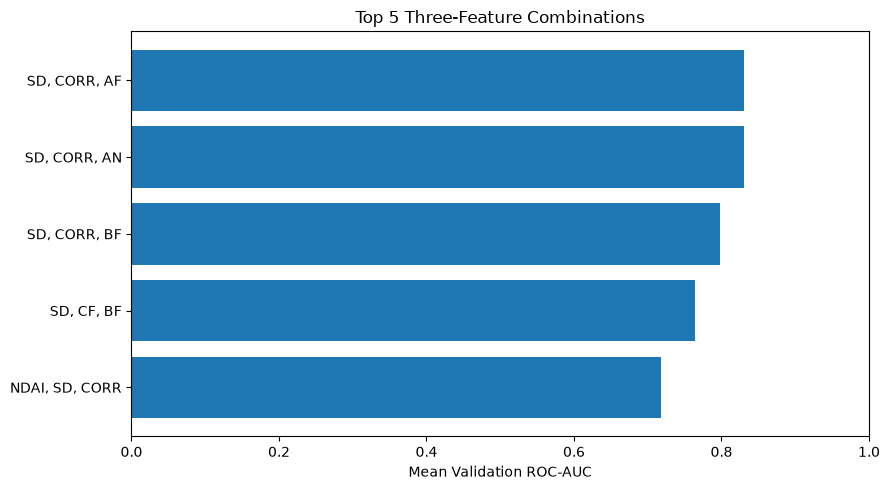

In [11]:
top = combo_df.head(5).copy()
top["Features"] = top["Features"].apply(lambda x: ", ".join(x))

plt.figure(figsize=(9, 5))
plt.barh(top["Features"], top["Mean AUC"])
plt.xlabel("Mean Validation ROC-AUC")
plt.title("Top 5 Three-Feature Combinations")
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

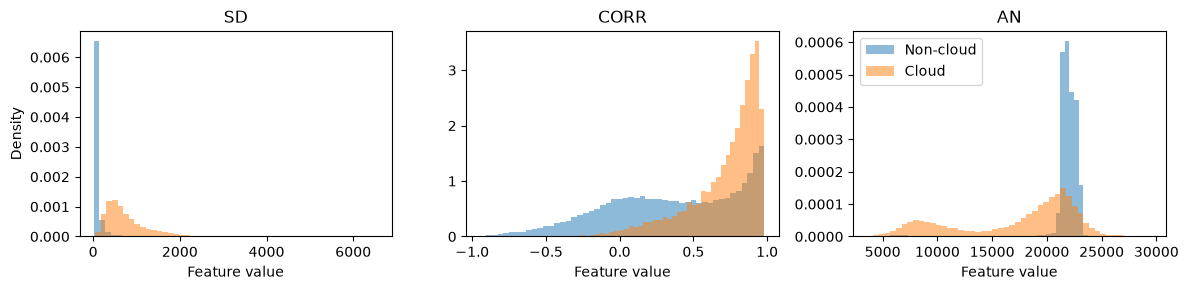

In [12]:
selected = ["SD", "CORR", "AN"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, feature in zip(axes, selected):
    i = FEATURES.index(feature)

    ax.hist(X1[y1 == -1, i], bins=50, density=True,
            alpha=0.5, label="Non-cloud")
    ax.hist(X1[y1 == 1, i], bins=50, density=True,
            alpha=0.5, label="Cloud")

    ax.set_title(feature)
    ax.set_xlabel("Feature value")

axes[0].set_ylabel("Density")
axes[-1].legend()

plt.tight_layout()
plt.show()

### Result
SD shows a clear difference between cloud and non-cloud pixels. Non-cloud pixels are concentrated at low SD values, while cloud pixels have a wider distribution.

CORR also shows differences between the classes, with cloud pixels more concentrated at higher values. AN has substantial overlap between the two classes, although cloud pixels extend toward lower radiance values.

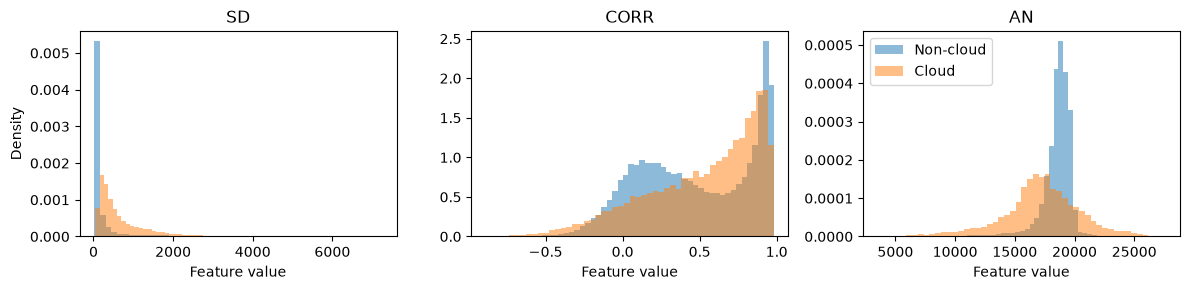

In [13]:
selected = ["SD", "CORR", "AN"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, feature in zip(axes, selected):
    i = FEATURES.index(feature)

    ax.hist(X2[y2 == -1, i], bins=50, density=True,
            alpha=0.5, label="Non-cloud")
    ax.hist(X2[y2 == 1, i], bins=50, density=True,
            alpha=0.5, label="Cloud")

    ax.set_title(feature)
    ax.set_xlabel("Feature value")

axes[0].set_ylabel("Density")
axes[-1].legend()

plt.tight_layout()
plt.show()

### Result
SD continues to distinguish cloud and non-cloud pixels relatively well, supporting its consistency across images.

In contrast, CORR and AN show considerable overlap between the two classes. These differences highlight the importance of evaluating features across multiple images rather than relying on a single image.

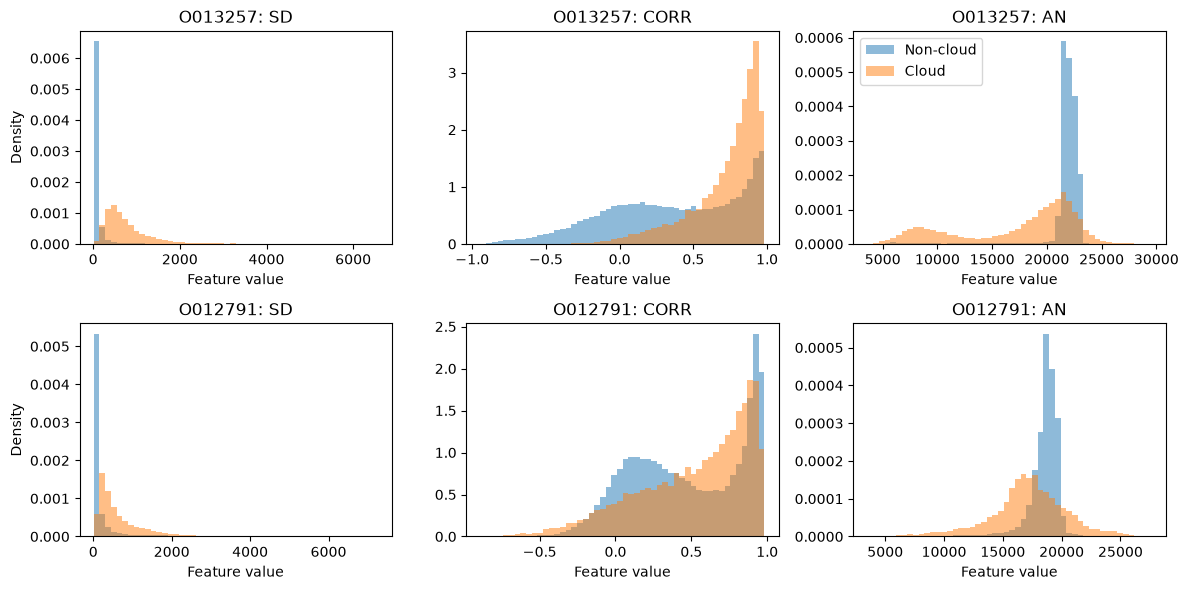

In [14]:
selected = ["SD", "CORR", "AN"]

fig, axes = plt.subplots(2, 3, figsize=(12, 6))

for row, (X, y, image) in enumerate([
    (X1, y1, "O013257"),
    (X2, y2, "O012791")
]):
    for col, feature in enumerate(selected):
        i = FEATURES.index(feature)
        ax = axes[row, col]

        bins = np.histogram_bin_edges(X[:, i], bins=50)

        ax.hist(X[y == -1, i], bins=bins, density=True,
                alpha=0.5, label="Non-cloud")
        ax.hist(X[y == 1, i], bins=bins, density=True,
                alpha=0.5, label="Cloud")

        ax.set_title(f"{image}: {feature}")
        ax.set_xlabel("Feature value")

        if col == 0:
            ax.set_ylabel("Density")

axes[0, 2].legend()
plt.tight_layout()
plt.show()

### Result
The combined visualization shows that SD provides relatively consistent separation between cloud and non-cloud pixels across both images, while CORR and AN have more overlapping distributions.

Together with the cross-image validation results, these patterns support selecting SD, CORR, and AN as three informative features.

In [15]:
fig.savefig("../figs/feature_distributions.pdf", bbox_inches="tight")

### Conclusion: Selection of Three Informative Features

Based on individual ROC-AUC, cross-image consistency, and logistic regression performance across all 56 three-feature combinations, we select **SD, CORR, and AN** as our preferred features.

SD demonstrates the strongest individual discriminatory power across both images. CORR and AN provide additional predictive information when combined with SD.

The selected combination achieves a mean cross-image validation AUC of approximately **0.830**, compared with **0.564** when using all eight features in the same logistic regression framework.

However, this selection is based on only two labeled images. The selected features should be evaluated on the independent held-out test image after model development is complete.